In [14]:
!mamba install pandas
mamba install scikit-learn
pip install seaborn


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.013 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.535 seconds
All requested packages already installed.
mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Requirement pandas already satisfied.
Requirement matplotlib already satisfied.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")


In [16]:
import os
import sys

print("Current Directory:", os.getcwd())
print("\nAvailable Files:")
print(os.listdir())


Current Directory: /drive/notebooks/Reatail incremental/Notebooks

Available Files:
['Day2_Model_Comparison.ipynb', 'Day3_Model_Tuning.ipynb', 'Day4_Feature_Engineering.ipynb', 'Day4_Feature_Engineering_Ensemble.ipynb', 'Train.ipynb', 'predict.ipynb.', 'predict_cmp.ipynb']


In [17]:
for root, dirs, files in os.walk(".."):
    print(root, dirs, files)
    

.. ['Data', 'Notebooks', 'Src', 'models'] []
../Data [] ['Telco-Customer-Churn.csv']
../Notebooks [] ['Day2_Model_Comparison.ipynb', 'Day3_Model_Tuning.ipynb', 'Day4_Feature_Engineering.ipynb', 'Day4_Feature_Engineering_Ensemble.ipynb', 'Train.ipynb', 'predict.ipynb.', 'predict_cmp.ipynb']
../Src ['__pycache__'] ['__init__.py', 'preprocessing.py']
../Src/__pycache__ [] ['preprocessing.cpython-313.pyc']
../models [] ['champion_churn_pipeline.joblib', 'churn_pipeline.joblib', 'churn_v3.joblib', 'day2_champion_model.joblib', 'final_churn_model.joblib']


In [18]:
import sys
import os

sys.path.append(os.path.abspath("../Src"))

from preprocessing import clean_data, engineer_features, create_preprocessor


print("Preprocessing functions imported successfully!")


Preprocessing functions imported successfully!


In [20]:
df = pd.read_csv("../Data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [21]:
df = clean_data(df)

print("Data cleaning completed!")
print("Dataset shape:", df.shape)

df.head()


Data cleaning completed!
Dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [22]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


Training Shape: (5634, 19)
Testing Shape: (1409, 19)


In [23]:
preprocessor = create_preprocessor(X_train)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Processed Shape:", X_train_processed.shape)
print("Testing Processed Shape:", X_test_processed.shape)


Training Processed Shape: (5634, 45)
Testing Processed Shape: (1409, 45)


In [24]:
selector = SelectKBest(
    score_func=f_classif,
    k=min(20, X_train_processed.shape[1])
)

X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

X_test_selected = selector.transform(X_test_processed)

print("Before Feature Selection:", X_train_processed.shape)
print("After Feature Selection:", X_train_selected.shape)


Before Feature Selection: (5634, 45)
After Feature Selection: (5634, 20)


In [25]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)

rf_predictions = rf_model.predict(X_test_selected)
rf_probabilities = rf_model.predict_proba(X_test_selected)[:, 1]

print("Random Forest Training Completed!")


Random Forest Training Completed!


In [26]:
print("RANDOM FOREST RESULTS")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))


RANDOM FOREST RESULTS
Accuracy: 0.7998580553584103
Precision: 0.6513157894736842
Recall: 0.5294117647058824
F1 Score: 0.584070796460177
ROC-AUC: 0.8351236146632566

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier


In [31]:
boost_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=42
)

boost_model.fit(X_train_selected, y_train)

boost_predictions = boost_model.predict(X_test_selected)

boost_probabilities = boost_model.predict_proba(X_test_selected)[:, 1]

print("Boosting Model Training Completed!")


Boosting Model Training Completed!


In [32]:
print("BOOSTING RESULTS")

print("Accuracy:", accuracy_score(y_test, boost_predictions))
print("Precision:", precision_score(y_test, boost_predictions))
print("Recall:", recall_score(y_test, boost_predictions))
print("F1 Score:", f1_score(y_test, boost_predictions))
print("ROC-AUC:", roc_auc_score(y_test, boost_probabilities))

print("\n", classification_report(y_test, boost_predictions))


BOOSTING RESULTS
Accuracy: 0.7984386089425124
Precision: 0.6541095890410958
Recall: 0.5106951871657754
F1 Score: 0.5735735735735735
ROC-AUC: 0.8356816244284274

               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [33]:
comparison = pd.DataFrame({
    "Model": [
        "Day 3 Champion",
        "Day 4 Random Forest",
        "Day 4 HistGradientBoosting"
    ],
    "Accuracy": [
        0.8012,
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, boost_predictions)
    ],
    "Precision": [
        0.6459,
        precision_score(y_test, rf_predictions),
        precision_score(y_test, boost_predictions)
    ],
    "Recall": [
        0.5546,
        recall_score(y_test, rf_predictions),
        recall_score(y_test, boost_predictions)
    ],
    "ROC-AUC": [
        0.8296,
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, boost_probabilities)
    ]
})

comparison


,Model,Accuracy,Precision,Recall,ROC-AUC
0,Day 3 Champion,0.801200,0.645900,0.554600,0.829600
1,Day 4 Random Forest,0.799858,0.651316,0.529412,0.835124
2,Day 4 HistGradientBoosting,0.798439,0.654110,0.510695,0.835682


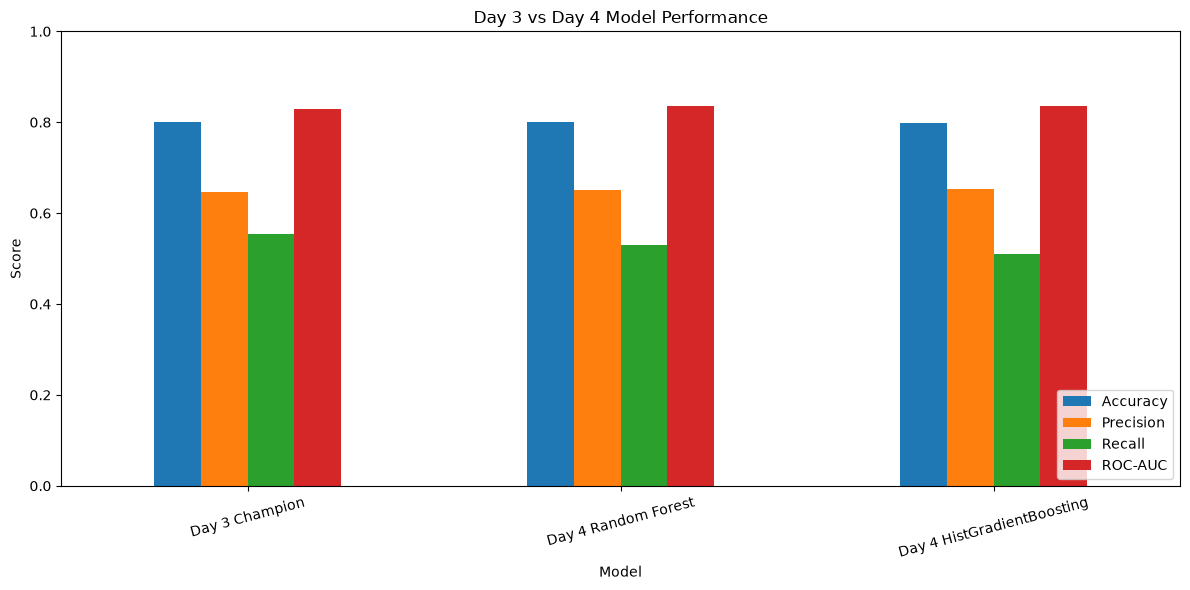

In [34]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Day 3 vs Day 4 Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [35]:
os.makedirs("../models", exist_ok=True)

joblib.dump(rf_model, "../models/day4_random_forest.joblib")

joblib.dump(
    boost_model,
    "../models/day4_hist_gradient_boosting.joblib"
)

joblib.dump(
    preprocessor,
    "../models/day4_preprocessor.joblib"
)

joblib.dump(
    selector,
    "../models/day4_feature_selector.joblib"
)

print("Day 4 models saved successfully!")


Day 4 models saved successfully!


In [36]:
df = engineer_features(df)

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Feature engineering and splitting completed!")
print(X_train.shape)


Feature engineering and splitting completed!
(5634, 33)


In [37]:
from sklearn.base import clone

rf_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(X_train)),
    ("selector", SelectKBest(f_classif, k=20)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

boost_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(X_train)),
    ("selector", SelectKBest(f_classif, k=20)),
    ("model", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ))
])

print("Complete pipelines created!")


Complete pipelines created!


In [38]:
rf_pipeline.fit(X_train, y_train)
boost_pipeline.fit(X_train, y_train)

print("Both complete pipelines trained!")


Both complete pipelines trained!


In [39]:
joblib.dump(
    rf_pipeline,
    "../models/day4_random_forest_pipeline.joblib"
)

joblib.dump(
    boost_pipeline,
    "../models/day4_boosting_pipeline.joblib"
)

print("Complete pipelines saved successfully!")


Complete pipelines saved successfully!
